In [2]:
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

print(df.head())


  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [3]:
print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nBasic statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Dataset dimensions:
(395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395

In [4]:
print("Number of students:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nAll column names:")
print(df.columns.tolist())

Number of students: 395
Number of columns: 33

All column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [5]:
print("Missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
0

Duplicate rows:
0

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [6]:
print(df["studytime"].value_counts().sort_index())

studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64
Average final grade by study-time category:
studytime
1    10.05
2    10.17
3    11.40
4    11.26
Name: G3, dtype: float64


In [7]:
average_grades = df.groupby("studytime")["G3"].mean()

print("Average final grade by study-time category:")
print(average_grades.round(2))

Average final grade by study-time category:
studytime
1    10.05
2    10.17
3    11.40
4    11.26
Name: G3, dtype: float64


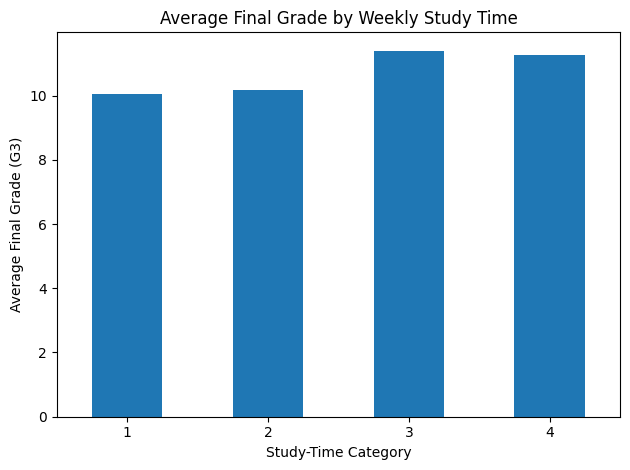

In [8]:
import matplotlib.pyplot as plt

average_grades.plot(kind="bar")

plt.title("Average Final Grade by Weekly Study Time")
plt.xlabel("Study-Time Category")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
failure_analysis = df.groupby("failures")["G3"].agg(
    ["count", "mean"]
)

failure_analysis.columns = [
    "Number of Students",
    "Average Final Grade"
]

print(failure_analysis.round(2))

          Number of Students  Average Final Grade
failures                                         
0                        312                11.25
1                         50                 8.12
2                         17                 6.24
3                         16                 5.69


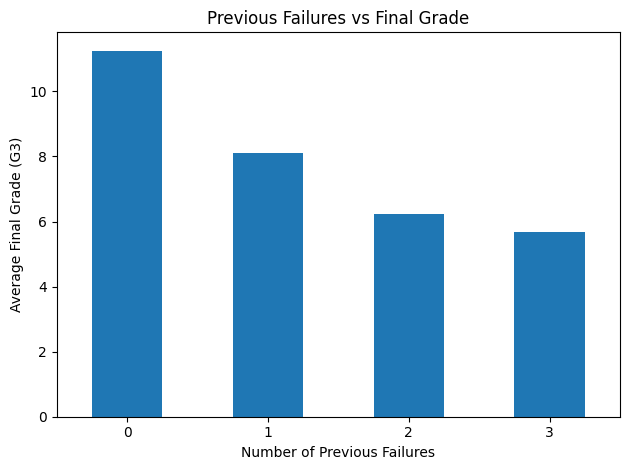

In [10]:
failure_analysis["Average Final Grade"].plot(
    kind="bar"
)

plt.title("Previous Failures vs Final Grade")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
df["absence_group"] = pd.cut(
    df["absences"],
    bins=[-1, 0, 2, 5, 10, float("inf")],
    labels=["0", "1-2", "3-5", "6-10", "11+"]
)

absence_analysis = df.groupby(
    "absence_group", observed=False
)["G3"].agg(["count", "mean"])

absence_analysis.columns = [
    "Number of Students",
    "Average Final Grade"
]

print(absence_analysis.round(2))

               Number of Students  Average Final Grade
absence_group                                         
0                             115                 8.44
1-2                            68                11.96
3-5                            66                11.33
6-10                           80                11.40
11+                            66                10.15


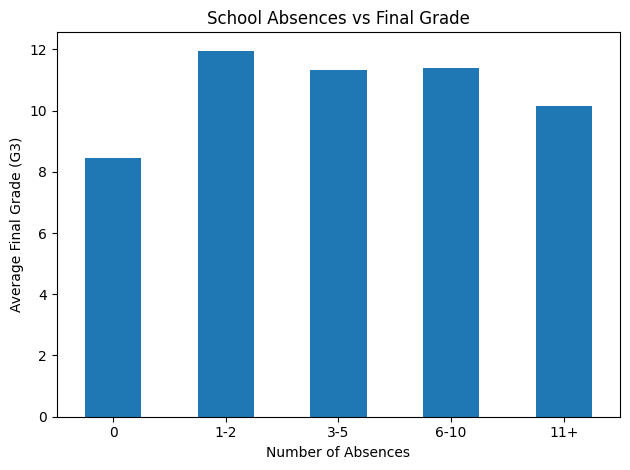

In [12]:
absence_analysis["Average Final Grade"].plot(
    kind="bar"
)

plt.title("School Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
print("Students in each absence group:")
print(df["absence_group"].value_counts().sort_index())

print("\nStudents in each previous-failure group:")
print(df["failures"].value_counts().sort_index())

Students in each absence group:
absence_group
0       115
1-2      68
3-5      66
6-10     80
11+      66
Name: count, dtype: int64

Students in each previous-failure group:
failures
0    312
1     50
2     17
3     16
Name: count, dtype: int64


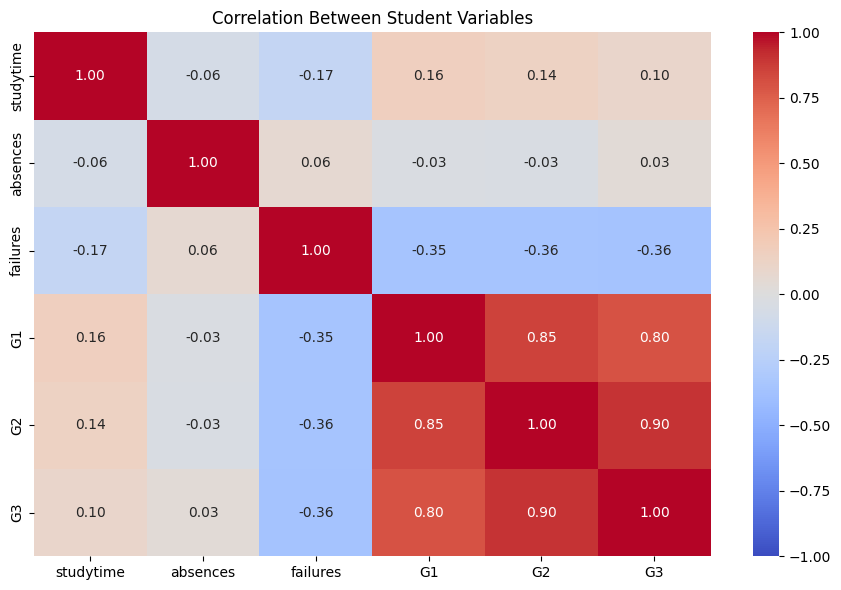

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

columns = [
    "studytime",
    "absences",
    "failures",
    "G1",
    "G2",
    "G3"
]

correlation_matrix = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Student Variables")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

X = df.drop(columns=["G1", "G2", "G3"])

numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("num", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), numeric_cols),
    ("cat", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, df["G3"], test_size=0.2, random_state=42
)

model_full = make_pipeline(
    preprocessor,
    Ridge(alpha=10)
)

model_full.fit(X_train, y_train)

predictions_full = model_full.predict(X_test)

print("Previous model MAE: 3.56")
print("New model MAE:",
      round(mean_absolute_error(y_test, predictions_full), 2))

print("Previous model R-squared: 0.031")
print("New model R-squared:",
      round(r2_score(y_test, predictions_full), 3))

Previous model MAE: 3.56
New model MAE: 3.29
Previous model R-squared: 0.031
New model R-squared: 0.199


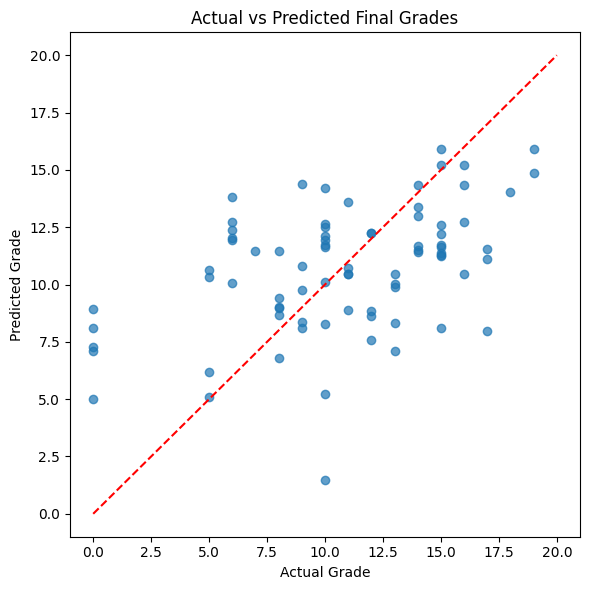

In [17]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, predictions_full, alpha=0.7)

plt.plot([0,20],[0,20], color="red", linestyle="--")

plt.xlabel("Actual Grade")
plt.ylabel("Predicted Grade")
plt.title("Actual vs Predicted Final Grades")

plt.tight_layout()
plt.show()

In [20]:
from sklearn.inspection import permutation_importance
import pandas as pd

result = permutation_importance(
    model_full,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

feature_names = X_test.columns

importance_df = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": result.importances_mean
    })
    .sort_values("Importance", ascending=False)
)

print(importance_df.head(10))

          Feature  Importance
14       failures    0.100859
30  absence_group    0.100133
25          goout    0.055684
1             sex    0.049636
8            Mjob    0.042576
6            Medu    0.031294
15      schoolsup    0.027219
9            Fjob    0.022835
2             age    0.021310
22       romantic    0.011587


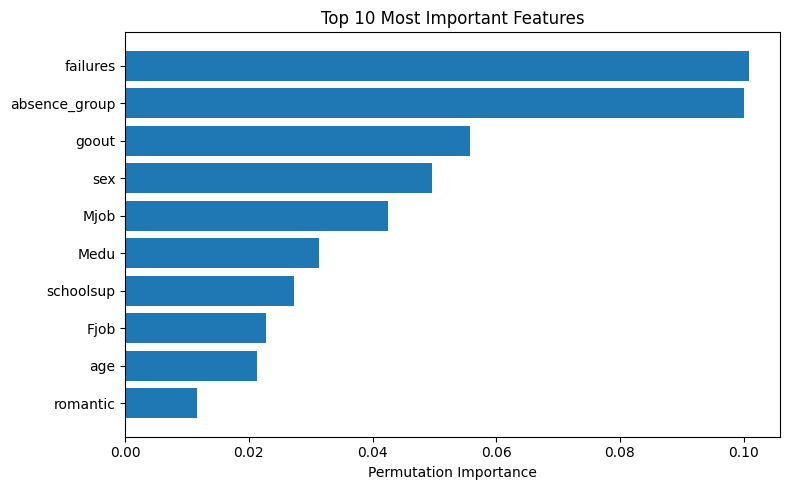

In [21]:
top10 = importance_df.head(10)

plt.figure(figsize=(8,5))

plt.barh(top10["Feature"], top10["Importance"])

plt.title("Top 10 Most Important Features")
plt.xlabel("Permutation Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [22]:
print("Original absences:")
print(df["absences"].describe())

print("\nGrouped absences:")
print(df["absence_group"].value_counts().sort_index())


Original absences:
count    395.000000
mean       5.708861
std        8.003096
min        0.000000
25%        0.000000
50%        4.000000
75%        8.000000
max       75.000000
Name: absences, dtype: float64

Grouped absences:
absence_group
0       115
1-2      68
3-5      66
6-10     80
11+      66
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import make_scorer, mean_absolute_error

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": make_pipeline(
        preprocessor,
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        preprocessor,
        Ridge(alpha=10)
    )
}

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        }
    )

    print("\n", name)
    print("Mean MAE:", round(-scores["test_mae"].mean(), 2))
    print("Mean R-squared:", round(scores["test_r2"].mean(), 3))


 Linear Regression
Mean MAE: 3.32
Mean R-squared: 0.12

 Ridge Regression
Mean MAE: 3.26
Mean R-squared: 0.152


In [24]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate, KFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyRegressor(strategy="mean")

models_to_compare = {
    "Mean Baseline": baseline,
    "Ridge Regression": make_pipeline(
        preprocessor,
        Ridge(alpha=10)
    )
}

for name, estimator in models_to_compare.items():
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        }
    )

    print("\n" + name)
    print("Mean MAE:", round(-scores["test_mae"].mean(), 2))
    print("Mean R-squared:", round(scores["test_r2"].mean(), 3))


Mean Baseline
Mean MAE: 3.43
Mean R-squared: -0.008

Ridge Regression
Mean MAE: 3.26
Mean R-squared: 0.152


## Model Evaluation and Results

### Models Compared

Three approaches were evaluated using five-fold cross-validation:

- **Mean Baseline:** Predicts the mean grade from each training fold.
- **Linear Regression:** Uses a linear relationship between the selected student features and final grade.
- **Ridge Regression:** Uses regularized linear regression to reduce the impact of overly large model coefficients.

### Cross-Validation Results

| Model | Mean MAE | Mean R² |
|---|---:|---:|
| Mean Baseline | 3.43 | -0.008 |
| Linear Regression | 3.32 | 0.120 |
| Ridge Regression | 3.26 | 0.152 |

### Conclusions

Ridge Regression achieved the lowest mean absolute error and highest mean R² among the three approaches. Its mean MAE was 0.17 grade points lower than the mean baseline.

The results suggest that student attributes contain some predictive information about final grades, although prediction accuracy remains limited. Further evaluation and feature engineering may improve performance.

These results are based on five-fold cross-validation with a fixed random seed. They should not be interpreted as proof that the model will perform equally well on every new dataset.